# NYC Taxi Demand Forecasting — External Factors

This notebook investigates whether external conditions help explain variation in Yellow Taxi demand beyond the historical and calendar patterns captured by the existing forecasting pipeline.

Weather is evaluated first because precipitation, temperature, snow, and other conditions may influence both overall travel behavior and travelers' choice of transportation mode.

## Objective

1. Load and validate historical NYC weather data.

2. Align weather observations with the hourly taxi demand panel.

3. Examine relationships between weather conditions and taxi demand.

4. Determine whether weather is associated with forecast errors from the historical-demand model.

5. Evaluate whether weather features provide incremental forecasting value using a new chronological evaluation design.

6. Identify additional external factors that may explain remaining demand variation.

## 1. Imports

Load the Python libraries used for weather-data preparation, exploratory analysis, and subsequent modeling.

In [114]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import meteostat as ms

from datetime import datetime
from pathlib import Path

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

processed_dir = Path("../data/processed")

In [119]:
from pathlib import Path

figures_dir = Path("../reports/figures")
figures_dir.mkdir(parents=True, exist_ok=True)

## 2. Inspect Weather Data Files

Inspect the available weather-data files before defining the ingestion process or selecting weather variables.

In [69]:
nyc = ms.Point(40.7789, -73.9692)

stations = ms.stations.nearby(nyc, limit=10)

stations

,name,country,region,latitude,longitude,elevation,timezone,distance
id,,,,,,,,
KNYC0,New York City / Yorkville,US,NY,40.77890,-73.96920,3,America/New_York,0.1
72503,LaGuardia Airport,US,NY,40.77917,-73.88000,7,America/New_York,7510.8
KJRB0,New York / Wall Street,US,NY,40.70120,-74.00900,2,America/New_York,9267.7
KTEB0,Teterboro,US,NJ,40.85010,-74.06080,3,America/New_York,11050.0
72502,Newark Airport,US,NJ,40.68250,-74.16944,5,America/New_York,19989.6
74486,John F. Kennedy Airport,US,NY,40.63330,-73.76670,4,America/New_York,23526.1
KCDW0,Caldwell / Fairfield,US,NJ,40.87520,-74.28140,52,America/New_York,28367.1
KLDJ0,Linden,US,NJ,40.61740,-74.24460,7,America/New_York,29351.6
KMMU0,Morristown / Birch Hills,US,NJ,40.79930,-74.41490,57,America/New_York,37591.0


In [70]:
print(stations[["name", "latitude", "longitude", "elevation"]])

                                      name  latitude  longitude  elevation
id                                                                        
KNYC0            New York City / Yorkville  40.77890  -73.96920          3
72503                    LaGuardia Airport  40.77917  -73.88000          7
KJRB0               New York / Wall Street  40.70120  -74.00900          2
KTEB0                            Teterboro  40.85010  -74.06080          3
72502                       Newark Airport  40.68250  -74.16944          5
74486              John F. Kennedy Airport  40.63330  -73.76670          4
KCDW0                 Caldwell / Fairfield  40.87520  -74.28140         52
KLDJ0                               Linden  40.61740  -74.24460          7
KMMU0             Morristown / Birch Hills  40.79930  -74.41490         57
KHPN0  White Plains / Sarosca Farm Estates  41.06690  -73.70760        134


### 2.1 Load Yorkville Hourly Weather

The New York City / Yorkville station (`KNYC0`) is evaluated as the primary weather source because it is located in Manhattan, where a large share of Yellow Taxi demand in the modeling panel occurs. Before using the station, its 2025 hourly coverage and variable completeness are validated.

In [71]:
station = ms.Station(id="KNYC0")

weather = ms.hourly(
    station,
    start,
    end,
    timezone="America/New_York"
).fetch()

weather.head()

,temp,rhum,prcp,snwd,wdir,wspd,wpgt,pres,tsun,cldc,coco
time,,,,,,,,,,,
2025-01-01 00:00:00-05:00,8.0,93,1.3,<NA>,59,7.0,<NA>,999.0,<NA>,8,5
2025-01-01 01:00:00-05:00,7.0,93,0.0,<NA>,300,6.0,<NA>,999.0,<NA>,8,5
2025-01-01 02:00:00-05:00,8.0,89,0.0,<NA>,40,7.0,<NA>,999.0,<NA>,8,5
2025-01-01 03:00:00-05:00,8.0,90,0.0,<NA>,220,6.0,<NA>,999.0,<NA>,8,5
2025-01-01 04:00:00-05:00,9.0,86,0.0,<NA>,242,9.0,<NA>,999.0,<NA>,8,5


In [72]:
print("Shape:", weather.shape)
print("Date range:", weather.index.min(), "to", weather.index.max())

print("\nMissing values:")
print(weather.isna().sum())

weather.info()

Shape: (8632, 11)
Date range: 2025-01-01 00:00:00-05:00 to 2025-12-31 23:00:00-05:00

Missing values:
temp       0
rhum       0
prcp      33
snwd    8632
wdir       2
wspd       2
wpgt    7638
pres     104
tsun    8632
cldc       6
coco      33
dtype: int64
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 8632 entries, 2025-01-01 00:00:00-05:00 to 2025-12-31 23:00:00-05:00
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   temp    8632 non-null   Float64
 1   rhum    8632 non-null   UInt8  
 2   prcp    8599 non-null   Float64
 3   snwd    0 non-null      UInt16 
 4   wdir    8630 non-null   UInt16 
 5   wspd    8630 non-null   Float64
 6   wpgt    994 non-null    Float64
 7   pres    8528 non-null   Float64
 8   tsun    0 non-null      UInt8  
 9   cldc    8626 non-null   UInt8  
 10  coco    8599 non-null   UInt8  
dtypes: Float64(5), UInt16(2), UInt8(4)
memory usage: 564.8 KB


## 3. Validate Temporal Coverage

The Yorkville station contains fewer observations than the 8,760 calendar hours in 2025. Missing timestamps are identified before weather data are merged with taxi demand so that absent weather observations are not silently treated as observed conditions.

In [73]:
expected_hours = pd.date_range(
    start="2025-01-01 00:00",
    end="2025-12-31 23:00",
    freq="h",
    tz="America/New_York"
)

missing_hours = expected_hours.difference(weather.index)

print("Expected hours:", len(expected_hours))
print("Observed weather hours:", len(weather))
print("Missing hours:", len(missing_hours))

missing_hours[:20]

Expected hours: 8760
Observed weather hours: 8632
Missing hours: 128


DatetimeIndex(['2025-03-14 21:00:00-04:00', '2025-03-14 22:00:00-04:00',
               '2025-03-14 23:00:00-04:00', '2025-03-15 00:00:00-04:00',
               '2025-03-15 01:00:00-04:00', '2025-03-15 03:00:00-04:00',
               '2025-03-15 04:00:00-04:00', '2025-03-15 05:00:00-04:00',
               '2025-03-15 06:00:00-04:00', '2025-03-15 07:00:00-04:00',
               '2025-03-15 09:00:00-04:00', '2025-03-15 10:00:00-04:00',
               '2025-03-15 11:00:00-04:00', '2025-03-15 12:00:00-04:00',
               '2025-03-15 13:00:00-04:00', '2025-03-15 15:00:00-04:00',
               '2025-03-15 16:00:00-04:00', '2025-03-15 17:00:00-04:00',
               '2025-03-15 18:00:00-04:00', '2025-03-15 19:00:00-04:00'],
              dtype='datetime64[ns, America/New_York]', freq=None)

In [74]:
missing_summary = (
    pd.Series(missing_hours)
    .dt.tz_localize(None)
    .dt.to_period("M")
    .value_counts()
    .sort_index()
)

missing_summary

2025-03    128
Freq: M, Name: count, dtype: int64

In [75]:
missing_summary = (
    pd.Series(missing_hours)
    .dt.tz_localize(None)
    .dt.to_period("M")
    .value_counts()
    .sort_index()
)

missing_summary

2025-03    128
Freq: M, Name: count, dtype: int64

In [76]:
weather.groupby(weather.index.month).size()

time
1     744
2     672
3     615
4     720
5     744
6     720
7     744
8     744
9     720
10    744
11    721
12    744
dtype: int64

## 4. Supplement Missing Weather Observations

The Yorkville station provides nearly complete 2025 coverage, but 128 hourly observations are missing during a concentrated period in March. Rather than interpolating across a multi-day station outage, observations from nearby LaGuardia Airport are used only when Yorkville data are unavailable.

This preserves Yorkville as the primary Manhattan weather source while avoiding synthetic weather estimates across an extended missing period.

In [77]:
laguardia = ms.Station(id="72503")

weather_lga = ms.hourly(
    laguardia,
    start,
    end,
    timezone="America/New_York"
).fetch()

print("LaGuardia observations:", len(weather_lga))
print("Date range:", weather_lga.index.min(), "to", weather_lga.index.max())
print("\nMissing values:")
print(weather_lga.isna().sum())

LaGuardia observations: 8760
Date range: 2025-01-01 00:00:00-05:00 to 2025-12-31 23:00:00-05:00

Missing values:
temp       0
rhum       0
prcp     473
snwd    8733
wdir       0
wspd       0
wpgt    7242
pres       0
tsun    8760
cldc       0
coco       0
dtype: int64


## 5. Construct Combined Weather Dataset

Yorkville is retained as the primary weather station because of its Manhattan location. For timestamps missing entirely from Yorkville, observations from LaGuardia Airport are substituted when available. A source indicator is retained so that the contribution of the backup station remains transparent.

In [78]:
weather_combined = weather.reindex(expected_hours)

weather_combined["weather_source"] = np.where(
    weather_combined["temp"].notna(),
    "Yorkville",
    "LaGuardia"
)

weather_combined = weather_combined.combine_first(
    weather_lga.reindex(expected_hours)
)

weather_combined.head()

,cldc,coco,prcp,pres,rhum,snwd,temp,tsun,wdir,weather_source,wpgt,wspd
2025-01-01 00:00:00-05:00,8,5,1.3,999.0,93,<NA>,8.0,<NA>,59,Yorkville,<NA>,7.0
2025-01-01 01:00:00-05:00,8,5,0.0,999.0,93,<NA>,7.0,<NA>,300,Yorkville,<NA>,6.0
2025-01-01 02:00:00-05:00,8,5,0.0,999.0,89,<NA>,8.0,<NA>,40,Yorkville,<NA>,7.0
2025-01-01 03:00:00-05:00,8,5,0.0,999.0,90,<NA>,8.0,<NA>,220,Yorkville,<NA>,6.0
2025-01-01 04:00:00-05:00,8,5,0.0,999.0,86,<NA>,9.0,<NA>,242,Yorkville,<NA>,9.0


In [79]:
print("Shape:", weather_combined.shape)
print("Date range:", weather_combined.index.min(), "to", weather_combined.index.max())

print("\nWeather source:")
print(weather_combined["weather_source"].value_counts())

print("\nMissing values:")
print(weather_combined.isna().sum())

Shape: (8760, 12)
Date range: 2025-01-01 00:00:00-05:00 to 2025-12-31 23:00:00-05:00

Weather source:
weather_source
Yorkville    8632
LaGuardia     128
Name: count, dtype: int64

Missing values:
cldc                 0
coco                 0
prcp                45
pres                 0
rhum                 0
snwd              8733
temp                 0
tsun              8760
wdir                 0
weather_source       0
wpgt              6947
wspd                 0
dtype: int64


In [80]:
backup_weather = weather_combined[
    weather_combined["weather_source"] == "LaGuardia"
]

print("Backup hours:", len(backup_weather))
print("First backup hour:", backup_weather.index.min())
print("Last backup hour:", backup_weather.index.max())

print("\nMissing values during backup period:")
print(backup_weather.isna().sum())

Backup hours: 128
First backup hour: 2025-03-14 21:00:00-04:00
Last backup hour: 2025-03-21 05:00:00-04:00

Missing values during backup period:
cldc                0
coco                0
prcp               39
pres                0
rhum                0
snwd              128
temp                0
tsun              128
wdir                0
weather_source      0
wpgt              128
wspd                0
dtype: int64


## 6. Select Weather Variables

Weather variables are selected based on both data completeness and a plausible relationship with transportation behavior. Temperature, relative humidity, precipitation, wind speed, cloud cover, and reported weather condition are retained.

Snow depth, sunshine duration, and peak wind gust are excluded because of extensive missingness. Wind direction and atmospheric pressure are also excluded from the initial analysis because they have less direct behavioral interpretation for taxi demand.

In [81]:
weather_features = weather_combined[
    [
        "temp",
        "rhum",
        "prcp",
        "wspd",
        "cldc",
        "coco",
        "weather_source"
    ]
].copy()

weather_features.isna().sum()

temp               0
rhum               0
prcp              45
wspd               0
cldc               0
coco               0
weather_source     0
dtype: int64

### 6.1 Handle Missing Precipitation

In [82]:
weather_features["prcp_imputed"] = weather_features["prcp"].isna().astype(int)

weather_features["prcp"] = (
    weather_features["prcp"]
    .interpolate(method="time")
)

print("Remaining missing values:")
print(weather_features.isna().sum())

print("\nImputed precipitation hours:")
print(weather_features["prcp_imputed"].sum())

Remaining missing values:
temp              0
rhum              0
prcp              0
wspd              0
cldc              0
coco              0
weather_source    0
prcp_imputed      0
dtype: int64

Imputed precipitation hours:
45


### 6.2 Create Interpretable Weather Features

In [83]:
weather_features["is_raining"] = (
    weather_features["prcp"] > 0
).astype(int)

weather_features["heavy_rain"] = (
    weather_features["prcp"] >= 2.5
).astype(int)

weather_features["is_freezing"] = (
    weather_features["temp"] <= 0
).astype(int)

In [84]:
print("Rain hours:", weather_features["is_raining"].sum())
print("Heavy rain hours:", weather_features["heavy_rain"].sum())
print("Freezing hours:", weather_features["is_freezing"].sum())

weather_features[
    ["temp", "rhum", "prcp", "wspd", "cldc"]
].describe()

Rain hours: 598
Heavy rain hours: 54
Freezing hours: 1114


,temp,rhum,prcp,wspd,cldc
count,8760.0,8760.0,8760.0,8760.0,8760.0
mean,12.985137,58.59395,0.058699,9.287694,4.365868
std,9.899244,19.144474,0.430717,6.169032,3.251606
min,-12.0,13.0,0.0,0.0,0.0
25%,5.0,43.0,0.0,6.0,1.0
50%,14.0,57.0,0.0,9.0,5.0
75%,21.0,74.0,0.0,13.0,8.0
max,37.0,100.0,14.5,44.6,8.0


In [85]:
weather_features[
    ["temp", "rhum", "prcp", "wspd", "cldc"]
].corr()

,temp,rhum,prcp,wspd,cldc
temp,1.000000,0.121651,-0.000438,-0.323242,-0.076361
rhum,0.121651,1.000000,0.168135,-0.197345,0.284237
prcp,-0.000438,0.168135,1.000000,0.021972,0.114516
wspd,-0.323242,-0.197345,0.021972,1.000000,0.044648
cldc,-0.076361,0.284237,0.114516,0.044648,1.000000


## 7. Merge Weather With Taxi Demand

The validated hourly weather observations are aligned with the zone-hour taxi-demand panel. Because taxi timestamps are stored as local clock times without timezone information, the weather timestamps are converted to timezone-naive New York local time before merging.

Each weather observation is shared across pickup zones for the corresponding hour, allowing weather conditions to be evaluated alongside zone-level demand.

In [86]:
weather_output = processed_dir / "nyc_hourly_weather_2025.parquet"

weather_features.reset_index().to_parquet(
    weather_output,
    index=False
)

print(f"Saved weather data to: {weather_output}")

Saved weather data to: ../data/processed/nyc_hourly_weather_2025.parquet


### 7.1 Load the Full Taxi-Demand Panel

In [87]:
demand_path = processed_dir / "yellow_taxi_hourly_demand_2025.parquet"

taxi_demand = pd.read_parquet(demand_path)

print("Shape:", taxi_demand.shape)
print("Date range:", taxi_demand["pickup_hour"].min(), "to", taxi_demand["pickup_hour"].max())
print("Zones:", taxi_demand["PULocationID"].nunique())

Shape: (1524240, 3)
Date range: 2025-01-01 00:00:00 to 2025-12-31 23:00:00
Zones: 174


### 7.2 Prepare Weather Timestamps

In [89]:
weather_merge = weather_features.reset_index()

weather_merge = weather_merge.rename(
    columns={weather_merge.columns[0]: "pickup_hour"}
)

weather_merge["pickup_hour"] = (
    weather_merge["pickup_hour"]
    .dt.tz_localize(None)
)

weather_merge.head()

,pickup_hour,temp,rhum,prcp,wspd,cldc,coco,weather_source,prcp_imputed,is_raining,heavy_rain,is_freezing
0,2025-01-01 00:00:00,8.0,93,1.3,7.0,8,5,Yorkville,0,1,0,0
1,2025-01-01 01:00:00,7.0,93,0.0,6.0,8,5,Yorkville,0,0,0,0
2,2025-01-01 02:00:00,8.0,89,0.0,7.0,8,5,Yorkville,0,0,0,0
3,2025-01-01 03:00:00,8.0,90,0.0,6.0,8,5,Yorkville,0,0,0,0
4,2025-01-01 04:00:00,9.0,86,0.0,9.0,8,5,Yorkville,0,0,0,0


In [90]:
print("Weather rows:", len(weather_merge))
print("Unique weather timestamps:", weather_merge["pickup_hour"].nunique())

duplicates = weather_merge[
    weather_merge["pickup_hour"].duplicated(keep=False)
]

duplicates[
    ["pickup_hour", "weather_source", "temp", "prcp", "wspd"]
]

Weather rows: 8760
Unique weather timestamps: 8759


,pickup_hour,weather_source,temp,prcp,wspd
7320,2025-11-02 01:00:00,Yorkville,9.0,0.0,0.0
7321,2025-11-02 01:00:00,Yorkville,8.0,0.0,0.0


## 8. Resolve Daylight Saving Time Duplicate

Converting timezone-aware weather observations to local timezone-naive timestamps creates one duplicate timestamp during the November daylight-saving transition, when 1:00 AM occurs twice.

Because the TLC taxi timestamps do not distinguish between the two occurrences of this local hour, the duplicate weather observations are combined into a single hourly record before merging. Continuous weather measurements are averaged, while binary weather indicators retain whether the condition occurred during either observation.

In [91]:
weather_merge = (
    weather_merge
    .groupby("pickup_hour", as_index=False)
    .agg({
        "temp": "mean",
        "rhum": "mean",
        "prcp": "mean",
        "wspd": "mean",
        "cldc": "mean",
        "coco": "first",
        "weather_source": "first",
        "prcp_imputed": "max",
        "is_raining": "max",
        "heavy_rain": "max",
        "is_freezing": "max"
    })
)

print("Weather rows after DST resolution:", len(weather_merge))
print("Unique timestamps:", weather_merge["pickup_hour"].nunique())
print("Duplicate timestamps:", weather_merge["pickup_hour"].duplicated().sum())

Weather rows after DST resolution: 8759
Unique timestamps: 8759
Duplicate timestamps: 0


## 9. Merge Weather and Taxi Demand

The cleaned hourly weather observations are joined to the complete zone-hour taxi-demand panel using local pickup hour. The merge is validated to ensure that weather integration does not duplicate or remove taxi-demand observations.

In [92]:
taxi_weather = taxi_demand.merge(
    weather_merge,
    on="pickup_hour",
    how="left",
    validate="many_to_one"
)

print("Original taxi rows:", len(taxi_demand))
print("Merged rows:", len(taxi_weather))

print("\nMissing values:")
print(taxi_weather.isna().sum())

Original taxi rows: 1524240
Merged rows: 1524240

Missing values:
pickup_hour         0
PULocationID        0
trip_count          0
temp              174
rhum              174
prcp              174
wspd              174
cldc              174
coco              174
weather_source    174
prcp_imputed      174
is_raining        174
heavy_rain        174
is_freezing       174
dtype: int64


In [93]:
missing_weather_rows = taxi_weather[
    taxi_weather["temp"].isna()
]

print("Rows without weather:", len(missing_weather_rows))
print(
    missing_weather_rows[
        ["pickup_hour", "PULocationID", "trip_count"]
    ].head()
)

print("\nMissing weather timestamps:")
print(missing_weather_rows["pickup_hour"].unique())

Rows without weather: 174
               pickup_hour  PULocationID  trip_count
280140 2025-03-09 02:00:00           237           0
280141 2025-03-09 02:00:00           161           0
280142 2025-03-09 02:00:00           132           0
280143 2025-03-09 02:00:00           236           0
280144 2025-03-09 02:00:00           186           0

Missing weather timestamps:
<DatetimeArray>
['2025-03-09 02:00:00']
Length: 1, dtype: datetime64[ns]


## 10. Remove Nonexistent Daylight Saving Time Hour

The balanced taxi-demand panel contains 174 zero-demand observations for March 9, 2025 at 2:00 AM—one for each pickup zone. This local clock hour did not occur because New York transitioned directly from 1:59 AM to 3:00 AM for daylight saving time.

Because these rows represent an artificial hour introduced when constructing the balanced 24-hour daily panel rather than an actual period of observed demand, they are removed from the weather-integrated dataset rather than assigning synthetic weather conditions.

In [94]:
taxi_weather = taxi_weather[
    taxi_weather["temp"].notna()
].copy()

print("Final rows:", len(taxi_weather))
print("Missing values:", taxi_weather.isna().sum().sum())
print(
    "Date range:",
    taxi_weather["pickup_hour"].min(),
    "to",
    taxi_weather["pickup_hour"].max()
)

Final rows: 1524066
Missing values: 0
Date range: 2025-01-01 00:00:00 to 2025-12-31 23:00:00


## 11. Weather and Taxi Demand

Raw demand differs substantially by hour of day and day of week, making a direct comparison between rainy and dry hours potentially misleading. To account for recurring weekly demand patterns, citywide hourly demand is compared with the typical demand observed during the same hour of the week.

This provides a descriptive measure of whether demand during particular weather conditions tends to be above or below its normal weekly pattern.

### 11.1 Aggregate Citywide Hourly Demand

In [95]:
hourly_citywide = (
    taxi_weather
    .groupby("pickup_hour", as_index=False)
    .agg({
        "trip_count": "sum",
        "temp": "first",
        "rhum": "first",
        "prcp": "first",
        "wspd": "first",
        "cldc": "first",
        "coco": "first",
        "is_raining": "first",
        "heavy_rain": "first",
        "is_freezing": "first"
    })
)

hourly_citywide["hour"] = hourly_citywide["pickup_hour"].dt.hour
hourly_citywide["day_of_week"] = hourly_citywide["pickup_hour"].dt.dayofweek

hourly_citywide.shape

(8759, 13)

### 11.2 Calculate Deviation From Typical Weekly Demand

In [96]:
hourly_citywide["typical_demand"] = (
    hourly_citywide
    .groupby(["day_of_week", "hour"])["trip_count"]
    .transform("mean")
)

hourly_citywide["demand_deviation_pct"] = (
    (
        hourly_citywide["trip_count"]
        - hourly_citywide["typical_demand"]
    )
    / hourly_citywide["typical_demand"]
    * 100
)

hourly_citywide[
    ["trip_count", "typical_demand", "demand_deviation_pct"]
].describe()

,trip_count,typical_demand,demand_deviation_pct
count,8759.000000,8759.000000,8.759000e+03
mean,5532.901701,5532.901701,3.115063e-16
std,3084.796821,2903.383710,2.726550e+01
min,160.000000,310.538462,-8.299688e+01
25%,2632.000000,2532.692308,-1.106472e+01
50%,6104.000000,6343.923077,5.288145e-01
75%,7724.500000,7833.173077,1.081504e+01
max,14009.000000,10804.615385,9.894768e+02


In [97]:
rain_comparison = (
    hourly_citywide
    .groupby("is_raining")
    .agg(
        hours=("pickup_hour", "count"),
        avg_demand=("trip_count", "mean"),
        avg_deviation_pct=("demand_deviation_pct", "mean")
    )
)

rain_comparison.index = ["Dry", "Rain"]

rain_comparison

,hours,avg_demand,avg_deviation_pct
Dry,8161,5489.643671,-0.247486
Rain,598,6123.250836,3.377483


**Observation:** Rainy hours averaged 6,123 Yellow Taxi pickups compared with 5,490 during dry hours. Because rainfall may occur disproportionately during naturally high- or low-demand periods, demand was also compared with the typical level for the same day of week and hour. After this adjustment, rainy hours averaged 3.38% above their normal weekly demand pattern, while dry hours averaged 0.25% below normal.

This suggests that rainfall is associated with moderately elevated Yellow Taxi demand beyond recurring weekly patterns. However, the comparison is descriptive and does not establish that rainfall itself causes the increase, since other seasonal, event, or travel-related factors may also differ between rainy and dry periods.

## 12. Rain Intensity and Demand

The initial comparison indicates higher-than-normal taxi demand during rainy hours. Because percentage deviations can be influenced by extreme observations during normally low-demand periods, both mean and median deviations are examined. Rainfall intensity is also separated to determine whether the relationship becomes stronger during wetter conditions.

In [98]:
rain_robustness = (
    hourly_citywide
    .groupby("is_raining")
    ["demand_deviation_pct"]
    .agg(["count", "mean", "median"])
)

rain_robustness.index = ["Dry", "Rain"]

rain_robustness

,count,mean,median
Dry,8161,-0.247486,0.269660
Rain,598,3.377483,2.294215


In [102]:
hourly_citywide["rain_category"] = np.select(
    [
        hourly_citywide["prcp"] == 0,
        (hourly_citywide["prcp"] > 0) & (hourly_citywide["prcp"] < 2.5),
        hourly_citywide["prcp"] >= 2.5
    ],
    [
        "Dry",
        "Light/Moderate Rain",
        "Heavy Rain"
    ],
    default="Unknown"
)

rain_intensity = (
    hourly_citywide
    .groupby("rain_category")
    .agg(
        hours=("pickup_hour", "count"),
        avg_demand=("trip_count", "mean"),
        mean_deviation_pct=("demand_deviation_pct", "mean"),
        median_deviation_pct=("demand_deviation_pct", "median")
    )
    .reindex(["Dry", "Light/Moderate Rain", "Heavy Rain"])
)

rain_intensity

,hours,avg_demand,mean_deviation_pct,median_deviation_pct
rain_category,,,,
Dry,8161,5489.643671,-0.247486,0.269660
Light/Moderate Rain,544,6091.279412,2.175747,1.924384
Heavy Rain,54,6445.333333,15.483864,12.972046


**Observation:** The association between rainfall and elevated taxi demand remains visible when median rather than mean demand deviations are examined. Rainy hours have a median demand deviation of 2.29% above their normal hour-of-week pattern, compared with 0.27% during dry conditions.

The relationship also becomes stronger with rainfall intensity. Light-to-moderate rain is associated with a median demand increase of 1.92%, while the 54 heavy-rain hours average 15.48% above normal and have a median deviation of 12.97%. This pattern is consistent with heavier rainfall being associated with greater Yellow Taxi demand, although the relatively small number of heavy-rain observations and potential confounding factors mean the results should not be interpreted as causal.

## 13. Temperature and Demand

Temperature may influence transportation behavior independently of precipitation, particularly during unusually cold or hot conditions. Demand deviations are therefore compared across temperature ranges to determine whether extreme temperatures are associated with departures from normal weekly taxi-demand patterns.

In [103]:
hourly_citywide["temp_category"] = pd.cut(
    hourly_citywide["temp"],
    bins=[-np.inf, 0, 10, 20, 30, np.inf],
    labels=[
        "Freezing (≤0°C)",
        "Cold (0–10°C)",
        "Mild (10–20°C)",
        "Warm (20–30°C)",
        "Hot (>30°C)"
    ],
    include_lowest=True
)

temperature_comparison = (
    hourly_citywide
    .groupby("temp_category", observed=True)
    .agg(
        hours=("pickup_hour", "count"),
        avg_demand=("trip_count", "mean"),
        mean_deviation_pct=("demand_deviation_pct", "mean"),
        median_deviation_pct=("demand_deviation_pct", "median")
    )
)

temperature_comparison

,hours,avg_demand,mean_deviation_pct,median_deviation_pct
temp_category,,,,
Freezing (≤0°C),1114,4864.830341,-7.964325,-7.614852
Cold (0–10°C),2440,5342.467623,-1.359135,-1.366360
Mild (10–20°C),2741,5433.623130,4.191453,4.036493
Warm (20–30°C),2314,6033.917027,-0.041303,-0.057536
Hot (>30°C),150,7677.326667,5.302347,2.922066


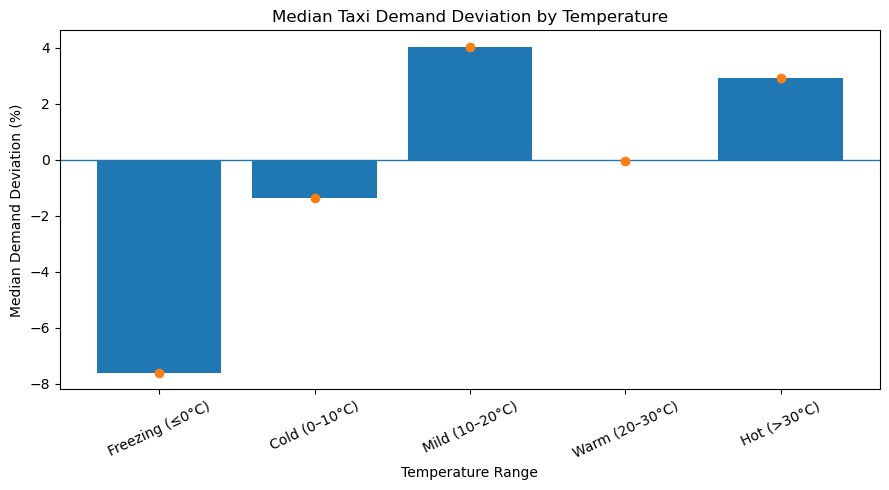

In [106]:
plt.figure(figsize=(9, 5))

x = np.arange(len(temperature_comparison))

plt.bar(
    x,
    temperature_comparison["median_deviation_pct"]
)

plt.scatter(
    x,
    temperature_comparison["median_deviation_pct"],
    zorder=3
)

plt.axhline(0, linewidth=1)

plt.xticks(
    x,
    temperature_comparison.index.astype(str),
    rotation=25
)

plt.title("Median Taxi Demand Deviation by Temperature")
plt.xlabel("Temperature Range")
plt.ylabel("Median Demand Deviation (%)")
plt.tight_layout()
plt.show()

**Observation:** Taxi demand does not exhibit a simple monotonic relationship with temperature. Freezing hours have a median demand deviation of 7.61% below their normal weekly pattern, while mild conditions are associated with a 4.04% increase. Warm conditions are approximately neutral, and the relatively small set of hot hours has a median deviation of 2.92% above normal.

Unlike the rainfall results, the temperature pattern does not show a consistent progression as conditions become more extreme. Temperature is also strongly tied to season, so these descriptive differences may reflect seasonal travel patterns or other time-varying factors rather than an independent temperature effect. This makes temperature a candidate feature for forecasting evaluation, but not strong evidence by itself of a direct relationship with taxi demand.

## 14. Wind Speed and Demand

Wind speed is examined as an additional measure of potentially unpleasant travel conditions. Because there is no single threshold that clearly defines behaviorally meaningful wind conditions, observations are divided into quartiles based on the 2025 wind-speed distribution.

In [107]:
hourly_citywide["wind_category"] = pd.qcut(
    hourly_citywide["wspd"],
    q=4,
    labels=["Lowest", "Low-Mid", "High-Mid", "Highest"]
)

wind_comparison = (
    hourly_citywide
    .groupby("wind_category", observed=True)
    .agg(
        hours=("pickup_hour", "count"),
        avg_wind_speed=("wspd", "mean"),
        mean_deviation_pct=("demand_deviation_pct", "mean"),
        median_deviation_pct=("demand_deviation_pct", "median")
    )
)

wind_comparison

,hours,avg_wind_speed,mean_deviation_pct,median_deviation_pct
wind_category,,,,
Lowest,2846,3.082256,1.869717,1.861744
Low-Mid,2302,7.875326,0.220423,0.726311
High-Mid,1765,11.681246,-1.459627,-0.535834
Highest,1846,18.332449,-1.761856,-1.384917


**Observation:** Taxi demand generally decreases as wind speed increases. Hours in the lowest wind-speed group have a median demand deviation of 1.86% above their normal weekly pattern, while hours in the highest group have a median deviation of 1.38% below normal.

The relationship is modest and may reflect seasonal or broader weather differences rather than an independent effect of wind speed. Compared with precipitation, wind therefore provides weaker descriptive evidence of a meaningful relationship with Yellow Taxi demand.

## 15. Leakage-Safe Weather Features

Observed weather at the target hour would not be known exactly when generating a one-hour-ahead taxi-demand forecast. Using realized target-hour weather as a model input would therefore overstate the information available in a realistic forecasting setting.

A production system could instead use a one-hour-ahead weather forecast. Because archived weather forecasts are not available in this project, the forecasting experiment uses weather observed one hour earlier. This preserves the one-hour-ahead information boundary while still testing whether recent weather conditions provide incremental predictive value beyond historical taxi demand.

In [108]:
weather_model = (
    weather_merge
    .sort_values("pickup_hour")
    .copy()
)

weather_model["temp_lag1"] = weather_model["temp"].shift(1)
weather_model["rhum_lag1"] = weather_model["rhum"].shift(1)
weather_model["prcp_lag1"] = weather_model["prcp"].shift(1)
weather_model["wspd_lag1"] = weather_model["wspd"].shift(1)
weather_model["cldc_lag1"] = weather_model["cldc"].shift(1)

weather_model["is_raining_lag1"] = weather_model["is_raining"].shift(1)
weather_model["heavy_rain_lag1"] = weather_model["heavy_rain"].shift(1)
weather_model["is_freezing_lag1"] = weather_model["is_freezing"].shift(1)

weather_lag_features = weather_model[
    [
        "pickup_hour",
        "temp_lag1",
        "rhum_lag1",
        "prcp_lag1",
        "wspd_lag1",
        "cldc_lag1",
        "is_raining_lag1",
        "heavy_rain_lag1",
        "is_freezing_lag1"
    ]
].copy()

In [109]:
model_data = pd.read_parquet(
    processed_dir / "yellow_taxi_modeling_features_2025.parquet"
)

weather_model_data = model_data.merge(
    weather_lag_features,
    on="pickup_hour",
    how="left",
    validate="many_to_one"
)

print("Original modeling rows:", len(model_data))
print("Weather modeling rows:", len(weather_model_data))

print("\nMissing weather features:")
print(
    weather_model_data[
        [
            "temp_lag1",
            "rhum_lag1",
            "prcp_lag1",
            "wspd_lag1",
            "cldc_lag1",
            "is_raining_lag1",
            "heavy_rain_lag1",
            "is_freezing_lag1"
        ]
    ].isna().sum()
)

Original modeling rows: 1495008
Weather modeling rows: 1495008

Missing weather features:
temp_lag1           174
rhum_lag1           174
prcp_lag1           174
wspd_lag1           174
cldc_lag1           174
is_raining_lag1     174
heavy_rain_lag1     174
is_freezing_lag1    174
dtype: int64


In [110]:
missing_weather_model = weather_model_data[
    weather_model_data["temp_lag1"].isna()
]

print("Rows with missing lagged weather:", len(missing_weather_model))

print("\nAffected timestamps:")
print(missing_weather_model["pickup_hour"].unique())

missing_weather_model[
    ["pickup_hour", "PULocationID", "trip_count"]
].head()

Rows with missing lagged weather: 174

Affected timestamps:
<DatetimeArray>
['2025-03-09 02:00:00']
Length: 1, dtype: datetime64[ns]


,pickup_hour,PULocationID,trip_count
1442,2025-03-09 02:00:00,4,0
10034,2025-03-09 02:00:00,7,0
18626,2025-03-09 02:00:00,10,0
27218,2025-03-09 02:00:00,12,0
35810,2025-03-09 02:00:00,13,0


**Observation:** All 174 missing lagged-weather observations correspond to March 9, 2025 at 2:00 AM, the nonexistent local hour created by the spring daylight-saving transition. Each pickup zone has zero recorded trips during this artificial hour.

Because this timestamp represents a structural artifact of the balanced taxi panel rather than an actual forecasting period, these rows are excluded from the weather-modeling experiment rather than imputing weather conditions for a time that did not occur.

In [111]:
weather_model_data = (
    weather_model_data[
        weather_model_data["temp_lag1"].notna()
    ]
    .copy()
)

print("Final weather-modeling rows:", len(weather_model_data))
print("Missing values:", weather_model_data.isna().sum().sum())

Final weather-modeling rows: 1494834
Missing values: 0


## 16. Expanding-Window Weather Ablation

The value of weather is evaluated using an expanding-window backtest from July through November 2025. For each evaluation month, models are trained exclusively on observations occurring before that month.

Two Random Forest models with identical hyperparameters are compared within every fold. The baseline model uses the historical-demand and calendar features developed previously, while the weather-augmented model adds one-hour-lagged weather features.

This paired design isolates the incremental predictive value of recent weather while preserving chronological ordering. December is excluded because it was already examined during the original model evaluation and therefore is not treated as an untouched test period for this new experiment.

In [112]:
base_features = [
    "PULocationID",
    "hour",
    "day_of_week",
    "month",
    "day_of_month",
    "is_weekend",
    "is_holiday",
    "lag_1",
    "lag_24",
    "lag_168",
    "rolling_mean_24",
    "rolling_mean_168"
]

weather_features_model = [
    "temp_lag1",
    "rhum_lag1",
    "prcp_lag1",
    "wspd_lag1",
    "cldc_lag1",
    "is_raining_lag1",
    "heavy_rain_lag1",
    "is_freezing_lag1"
]

all_weather_features = base_features + weather_features_model

target = "trip_count"

In [113]:
print("Base features:")
print(base_features)

print("\nAll features available:")
print(
    all(
        col in weather_model_data.columns
        for col in all_weather_features
    )
)

print("\nMissing columns:")
print([
    col
    for col in all_weather_features
    if col not in weather_model_data.columns
])

Base features:
['PULocationID', 'hour', 'day_of_week', 'month', 'day_of_month', 'is_weekend', 'is_holiday', 'lag_1', 'lag_24', 'lag_168', 'rolling_mean_24', 'rolling_mean_168']

All features available:
True

Missing columns:
[]


## 17. Compare Baseline and Weather-Augmented Models

For each monthly backtest fold, the baseline and weather-augmented models are trained on exactly the same historical observations and evaluated on exactly the same future month. Both models use the Random Forest configuration selected during the original modeling stage.

Mean absolute error is retained as the primary metric, with root mean squared error reported as a secondary measure. Improvement is calculated relative to the baseline model within each fold.

In [115]:
evaluation_months = [
    ("July", "2025-07-01", "2025-08-01"),
    ("August", "2025-08-01", "2025-09-01"),
    ("September", "2025-09-01", "2025-10-01"),
    ("October", "2025-10-01", "2025-11-01"),
    ("November", "2025-11-01", "2025-12-01")
]

results = []

for month_name, start_date, end_date in evaluation_months:
    
    train_mask = weather_model_data["pickup_hour"] < start_date
    
    eval_mask = (
        (weather_model_data["pickup_hour"] >= start_date) &
        (weather_model_data["pickup_hour"] < end_date)
    )
    
    train_fold = weather_model_data.loc[train_mask]
    eval_fold = weather_model_data.loc[eval_mask]
    
    print(
        f"{month_name}: "
        f"{len(train_fold):,} training rows, "
        f"{len(eval_fold):,} evaluation rows"
    )
    
    # Baseline model
    base_model = RandomForestRegressor(
        n_estimators=100,
        max_depth=20,
        min_samples_leaf=5,
        n_jobs=-1,
        random_state=42
    )
    
    base_model.fit(
        train_fold[base_features],
        train_fold[target]
    )
    
    base_pred = base_model.predict(
        eval_fold[base_features]
    )
    
    base_mae = mean_absolute_error(
        eval_fold[target],
        base_pred
    )
    
    base_rmse = np.sqrt(
        mean_squared_error(
            eval_fold[target],
            base_pred
        )
    )
    
    # Weather-augmented model
    weather_model_rf = RandomForestRegressor(
        n_estimators=100,
        max_depth=20,
        min_samples_leaf=5,
        n_jobs=-1,
        random_state=42
    )
    
    weather_model_rf.fit(
        train_fold[all_weather_features],
        train_fold[target]
    )
    
    weather_pred = weather_model_rf.predict(
        eval_fold[all_weather_features]
    )
    
    weather_mae = mean_absolute_error(
        eval_fold[target],
        weather_pred
    )
    
    weather_rmse = np.sqrt(
        mean_squared_error(
            eval_fold[target],
            weather_pred
        )
    )
    
    results.append({
        "month": month_name,
        "base_mae": base_mae,
        "weather_mae": weather_mae,
        "mae_improvement_pct": (
            (base_mae - weather_mae) / base_mae * 100
        ),
        "base_rmse": base_rmse,
        "weather_rmse": weather_rmse,
        "rmse_improvement_pct": (
            (base_rmse - weather_rmse) / base_rmse * 100
        )
    })
    
    # Free memory before next fold
    del base_model
    del weather_model_rf
    del base_pred
    del weather_pred

backtest_results = pd.DataFrame(results)

backtest_results.round(3)

July: 726,450 training rows, 129,456 evaluation rows
August: 855,906 training rows, 129,456 evaluation rows
September: 985,362 training rows, 125,280 evaluation rows
October: 1,110,642 training rows, 129,456 evaluation rows
November: 1,240,098 training rows, 125,280 evaluation rows


,month,base_mae,weather_mae,mae_improvement_pct,base_rmse,weather_rmse,rmse_improvement_pct
0,July,5.501,5.539,-0.692,13.451,13.491,-0.299
1,August,4.725,4.729,-0.084,11.059,11.061,-0.023
2,September,5.585,5.624,-0.692,13.661,13.820,-1.162
3,October,5.274,5.293,-0.358,12.893,12.933,-0.310
4,November,5.684,5.734,-0.878,14.124,14.236,-0.793


In [116]:
summary = pd.DataFrame({
    "Metric": [
        "Average Base MAE",
        "Average Weather MAE",
        "Average MAE Improvement (%)",
        "Months Weather Improved MAE",
        "Average Base RMSE",
        "Average Weather RMSE",
        "Average RMSE Improvement (%)",
        "Months Weather Improved RMSE"
    ],
    "Value": [
        backtest_results["base_mae"].mean(),
        backtest_results["weather_mae"].mean(),
        backtest_results["mae_improvement_pct"].mean(),
        (backtest_results["weather_mae"] < backtest_results["base_mae"]).sum(),
        backtest_results["base_rmse"].mean(),
        backtest_results["weather_rmse"].mean(),
        backtest_results["rmse_improvement_pct"].mean(),
        (backtest_results["weather_rmse"] < backtest_results["base_rmse"]).sum()
    ]
})

summary

,Metric,Value
0,Average Base MAE,5.353931
1,Average Weather MAE,5.383825
2,Average MAE Improvement (%),-0.540762
3,Months Weather Improved MAE,0.000000
4,Average Base RMSE,13.037505
5,Average Weather RMSE,13.108186
6,Average RMSE Improvement (%),-0.517298
7,Months Weather Improved RMSE,0.000000


**Observation:** Across the five expanding-window evaluation periods, the historical-demand baseline achieved an average MAE of 5.35 and RMSE of 13.04. Adding one-hour-lagged weather increased average MAE to 5.38 and RMSE to 13.11, corresponding to average performance changes of -0.54% and -0.52%, respectively. The weather-augmented model failed to improve either metric in any of the five evaluation months.

These results indicate that recent observed weather does not provide incremental forecasting value beyond the strong historical-demand and calendar features already included in the model. This does not imply that weather is unrelated to taxi demand: the exploratory analysis found substantially higher-than-normal demand during heavy rainfall. Instead, the forecasting experiment suggests that one-hour-lagged weather does not contain enough additional information to improve the existing model. A production system could test whether actual one-hour-ahead weather forecasts provide more useful information about conditions at the prediction timestamp.

## 18. Weather Analysis Conclusions

Weather shows meaningful descriptive relationships with Yellow Taxi demand, but those relationships do not automatically translate into improved one-hour-ahead forecasts.

Heavy-rain hours showed the strongest pattern, with median demand approximately 13% above the normal level for the same day of week and hour. Temperature displayed a less consistent relationship, while higher wind speeds were associated with modestly lower-than-normal demand.

However, a five-month expanding-window ablation showed that adding one-hour-lagged weather features slightly worsened both MAE and RMSE in every evaluation month. The historical-demand model therefore remains the preferred forecasting specification.

This result highlights an important distinction between explanation and prediction: an external factor may be associated with demand while still providing little incremental forecasting value once strong historical patterns are already represented. Future work could evaluate archived one-hour-ahead weather forecasts, which would provide information about conditions at the target hour without violating the forecasting information boundary.

## 19. Limitations and Future Work

This analysis uses observations from a single Manhattan weather station, supplemented by LaGuardia Airport during a temporary station outage. As a result, localized weather variation across New York City is not represented.

The forecasting experiment also uses one-hour-lagged observed weather rather than historical weather forecasts. While this preserves the forecasting information boundary, it may be less informative than an actual one-hour-ahead forecast of conditions at the target timestamp.

Future work could incorporate archived weather forecasts and additional scheduled external signals such as major sporting events, concerts, conventions, airport activity, or transit disruptions. These factors may be particularly useful for anticipating abrupt localized demand changes that are difficult to infer from historical taxi demand alone.

In [117]:
weather_output = processed_dir / "nyc_taxi_weather_analysis_2025.parquet"

taxi_weather.to_parquet(
    weather_output,
    index=False
)

print(f"Saved: {weather_output}")

Saved: ../data/processed/nyc_taxi_weather_analysis_2025.parquet


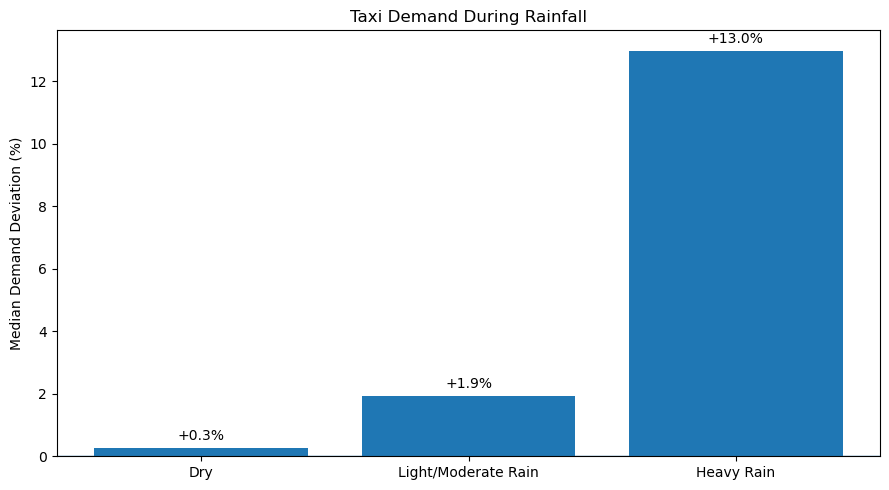

In [120]:
rain_plot = pd.DataFrame({
    "Condition": [
        "Dry",
        "Light/Moderate Rain",
        "Heavy Rain"
    ],
    "Median Demand Deviation": [
        0.2697,
        1.9244,
        12.9720
    ]
})

plt.figure(figsize=(9, 5))

bars = plt.bar(
    rain_plot["Condition"],
    rain_plot["Median Demand Deviation"]
)

plt.axhline(0, linewidth=1)

plt.ylabel("Median Demand Deviation (%)")
plt.title("Taxi Demand During Rainfall")

for bar, value in zip(
    bars,
    rain_plot["Median Demand Deviation"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.25,
        f"{value:+.1f}%",
        ha="center"
    )

plt.tight_layout()

plt.savefig(
    figures_dir / "rainfall_demand.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

**Observation:** Demand increased with rainfall intensity after normalizing for typical day-of-week and hour patterns. Heavy-rain hours showed approximately 13% higher median demand than expected, although only 54 heavy-rain hours were observed during the year. This relationship is descriptive rather than causal and did not translate into improved forecasting performance when leakage-safe lagged weather features were tested.